# Dynamic ORB Strategy
### Utilizing local LLMs
***
This strategy utilizes a *dynamic* opening range system that uses time series to determine which time frame range (1m, 3m, 5m, 15m, 30m, and so on) has the ***highest probability*** of profiting.
This model will also utilize local LLMs (as well as other means of AI & ML) for further decision reasoning.

This model will be utilizing: 
- a volume profile which is used to deterimne which side has/had the most control during that range
- MBO (and aggregated 1m OHLCV) data will be used to identify supply and demand zones for determining where the most likely amount of buying/selling  interest is 
- a 1.25x ATR will be used for calculating the initial stop-loss for risk manage ment (60/40 trailing stop)
- llama3.2:1b for reasoning and advanced decision making (***experimental***)
- NN systems for training the model on high probability ORB ranges
- A time series and monte carlo simulator the test which ORB variation should be used for the given trading session
- a rolling window walk forward analysis backtest to determine viability
***

So far current backtest has yieled **$56,011** with a sharpe of **0.84** on a **2 year long 1m-OHLCV year sample set/size** 

### ***This strategy is meant to be used intradaily with prop-firms having EOD drawdown (Topstep, MFF, Take profit trader, etc)***

# Module.1
### Data/Library importing

In [33]:
"""Cell Block 1"""


import glob
from pathlib import Path
import databento as db
import pandas as pd
import random as rn
import os
import ollama # type: ignore
from collections import defaultdict
import matplotlib.pyplot as plt
import numpy as np
import datetime
import seaborn as sns
import scipy
import sklearn
import statsmodels
import ta # type: ignore
import torch # type: ignore
import torch.nn as nn # type: ignore
import yfinance as yf # type: ignore
import marketwatch as mw # type: ignore

In [ ]:
"""Cell Block 2"""


csv_path = Path('/Users/andrew/main/Trading/Data/historical data/NQ/1m OHLCV data/NQ-2010.06.06-2026.01.23-ohlcv-1m.csv')

df_1m = pd.read_csv(
    csv_path,
    dtype={'open': 'float32', 'high': 'float32', 'low': 'float32', 'close': 'float32', 'volume': 'int32', 'instrument_id': 'int32', 'publisher_id': 'int32', 'rtype': 'int32'}
)

# Parse the timestamp column (already in UTC)
df_1m['ts_event'] = pd.to_datetime(df_1m['ts_event'], utc=True)
df_1m.set_index('ts_event', inplace=True)
df_1m.sort_index(inplace=True)

# Show available symbols
print("Unique symbols and counts:")
print(df_1m['symbol'].value_counts().head(20))

print(f"\nLoaded {len(df_1m)} rows, {df_1m.index.min()} to {df_1m.index.max()}")
df_1m.head()

Unique symbols and counts:
symbol
NQZ4    219888
NQZ5    210882
NQU2    210384
NQM2    210297
NQU5    210237
NQZ1    208772
NQM5    208123
NQZ3    207695
NQM4    206573
NQH5    204883
NQU4    204474
NQM3    203936
NQU1    203908
NQM1    201373
NQZ2    201010
NQH2    200626
NQZ0    199937
NQU3    198421
NQH4    197516
NQH1    194528
Name: count, dtype: int64

Loaded 6949239 rows, 2010-06-06 22:00:00+00:00 to 2026-01-23 21:59:00+00:00


,rtype,publisher_id,instrument_id,open,high,low,close,volume,symbol
ts_event,,,,,,,,,
2010-06-06 22:00:00+00:00,33,1,6641,1831.75,1831.75,1828.75,1829.00,117,NQM0
2010-06-06 22:00:00+00:00,33,1,26715,1833.50,1833.50,1827.75,1827.75,3,NQU0
2010-06-06 22:01:00+00:00,33,1,6641,1828.50,1831.00,1828.50,1830.50,99,NQM0
2010-06-06 22:02:00+00:00,33,1,6641,1830.50,1832.25,1830.50,1831.25,32,NQM0
2010-06-06 22:03:00+00:00,33,1,26715,1828.00,1828.00,1828.00,1828.00,1,NQU0


In [ ]:
"""Cell Block 3"""


# import MBO data
mbo_folders = [    
    '/Users/andrew/main/Trading/Data/historical data/NQ/MBO data/2025.07.28-2025.10.08',
    '/Users/andrew/main/Trading/Data/historical data/NQ/MBO data/2025.10.10-2025.12-17',
    '/Users/andrew/main/Trading/Data/historical data/NQ/MBO data/2025.12.18-2026.03.08',
    '/Users/andrew/main/Trading/Data/historical data/NQ/MBO data/2026.03.09-2026.05.19'
]

all_zst = []
for folder in mbo_folders:
    folder_path = Path(folder)
    if folder_path.exists():
        # Match DataBento .dbn.zst files
        all_zst.extend(glob.glob(str(folder_path / '*.dbn.zst')))
    else:
        print(f"⚠️  Folder not found: {folder}")

all_zst = sorted(all_zst)
print(f"Found {len(all_zst)} MBO files.")

if not all_zst:
    raise FileNotFoundError("No .dbn.zst files found. Check pattern or paths.")

Found 253 MBO files.


# Module.2a
### Indicators
***
The following indicators the model will use:
- Volume profile proxy with a POC (using aggregated 1m OHLCV & L3 MBO data)
- Delta per minute proxy (using aggregated 1m OHLCV & L3 MBO data)
- 1.25x ATR for risk management

### **Volume profile with POC (using MBO data)**


In [36]:
"""Cell Block 1"""


import random
from IPython.core import pylabtools
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
from pathlib import Path
from collections import defaultdict

# ============================================================================
#  VOLUME PROFILE WITH POC  — Using L3 MBO Trade Data
# ============================================================================
# This cell builds a true volume profile from MBO (Market-by-Order) trade
# data, identifies HVNs (High Volume Nodes), LVNs (Low Volume Nodes), and
# the POC (Point of Control), then overlays it on the day's 1-minute OHLCV
# candlestick chart.
#
# Each re-run picks a RANDOM overlapping date between OHLCV and MBO datasets.
# ============================================================================


# ---------- 1. Rebuild files_by_date if not already in memory ----------
if 'files_by_date' not in globals():
    files_by_date = defaultdict(list)
    for f in all_zst:
        name = Path(f).stem
        match = re.search(r'(\d{8})', name)
        if match:
            files_by_date[match.group(1)].append(f)
    print("Rebuilt files_by_date")


# ---------- 2. Pick a random overlapping date ----------
# Filter OHLCV to NQ outright contracts only (exclude spreads like NQU5-NQZ5)
ohlcv_nq = df_1m[df_1m['symbol'].str.match(r'^NQ[A-Z]\d$', na=False)]
ohlc_dates = pd.Series(ohlcv_nq.index.date).unique()
mbo_dates_set = {pd.Timestamp(d).date() for d in files_by_date.keys()}
overlap = sorted([d for d in ohlc_dates if d in mbo_dates_set])

if not overlap:
    raise ValueError("No overlapping dates between OHLCV and MBO data.")

chosen_date = random.choice(overlap)
print(f"Selected date: {chosen_date}")


# ---------- 3. Load MBO trades for that day ----------
# Find matching date key in files_by_date
possible_keys = [k for k in files_by_date if pd.Timestamp(k).date() == chosen_date]
if not possible_keys:
    raise ValueError(f"No MBO files for {chosen_date}")
date_key = possible_keys[0]

frames = []
for f in files_by_date[date_key]:
    store = db.DBNStore.from_file(f)
    frames.append(store.to_df())
day_mbo = pd.concat(frames, ignore_index=True)
day_mbo['ts_event'] = pd.to_datetime(day_mbo['ts_event'], utc=True)

# ── CRITICAL: DataBento to_df() already converts prices to real units ──
# DO NOT divide by 1e9. Prices are already in NQ point values (e.g., 23534.25).

# Filter to NQ outright contracts only (exclude spreads, far-months with
# minimal liquidity). This ensures the volume profile reflects tradeable
# front-month action, not inter-contract noise.
day_mbo = day_mbo[day_mbo['symbol'].str.match(r'^NQ[A-Z]\d$', na=False)]

# Extract executed trades only (action == 'T' is the matched trade message).
# Side semantics for Trade messages (per DataBento docs):
#   'A' = aggressor was a SELLER  (they hit the bid)
#   'B' = aggressor was a BUYER   (they lifted the ask)
#   'N' = no side specified        (rare, exclude)
trades = day_mbo[
    (day_mbo['action'] == 'T') & (day_mbo['side'] != 'N')
][['ts_event', 'side', 'price', 'size']].copy()

print(f"  Loaded {len(trades):,} NQ trades for {chosen_date}")
print(f"  Price range: {trades['price'].min():.2f} – {trades['price'].max():.2f}")


# ---------- 4. Build the volume profile ----------
# Bucket every trade to the nearest NQ tick (0.25 points).
# The profile aggregates total traded size at each price level — this is the
# gaussian-like distribution of volume that reveals where the market spent
# the most time and where it rejected price.
TICK = 0.25
trades['price_bucket'] = (trades['price'] / TICK).round() * TICK
vol_profile = trades.groupby('price_bucket')['size'].sum().sort_index()

# POC: the single price level with the highest traded volume
poc_price = vol_profile.idxmax()
poc_vol   = vol_profile.max()

# HVN / LVN classification via percentile thresholds.
# HVNs (>= 70th pctile) = "acceptance" zones — price was transacted heavily
# LVNs (<= 30th pctile) = "rejection" zones — price moved through quickly
high_thresh = vol_profile.quantile(0.70)
low_thresh  = vol_profile.quantile(0.30)
hvns = vol_profile[vol_profile >= high_thresh]
lvns = vol_profile[vol_profile <= low_thresh]

print(f"  POC: {poc_price:.2f}  (volume: {poc_vol:,})")
print(f"  HVNs: {len(hvns)} levels | LVNs: {len(lvns)} levels")


# ---------- 5. OHLCV for the same day (NQ outrights only) ----------
day_ohlc = ohlcv_nq[ohlcv_nq.index.date == chosen_date].copy().sort_index()

if day_ohlc.empty:
    raise ValueError(f"No OHLCV data found for {chosen_date} after symbol filter.")

# Keeps only the front-month (highest-volume) contract.
front_month = day_ohlc.groupby('symbol')['volume'].sum().idxmax()
day_ohlc = day_ohlc[day_ohlc['symbol'] == front_month]
print(f"  Front-month contract: {front_month}  ({len(day_ohlc)} bars)")


# ---------- 6. High-quality chart ----------
# Layout: 75% candlestick chart | 25% horizontal volume profile
fig = plt.figure(figsize=(16, 9), facecolor='#0e1117')
ax_price = plt.subplot2grid((1, 5), (0, 0), colspan=4)
ax_vol   = plt.subplot2grid((1, 5), (0, 4), sharey=ax_price)

# Style both axes with a dark trading-terminal aesthetic
for ax in [ax_price, ax_vol]:
    ax.set_facecolor('#0e1117')
    ax.tick_params(colors='#c9d1d9', labelsize=8)
    for spine in ax.spines.values():
        spine.set_color('#30363d')

# ── Candlestick chart (manual rendering for full control) ──
# Width of candle bodies in matplotlib date units (fraction of a day).
# For 1-min bars: 1 minute ≈ 1/1440 of a day. We use ~60% of that.
candle_width = (1.0 / 1440) * 0.6
dates_num = mdates.date2num(day_ohlc.index.to_pydatetime())

for d, o, h, l, c in zip(dates_num,
                          day_ohlc['open'], day_ohlc['high'],
                          day_ohlc['low'],  day_ohlc['close']):
    color = '#26a69a' if c >= o else '#ef5350'          # green / red
    body_bottom = min(o, c)
    body_height = abs(c - o) or TICK * 0.1              # prevent zero-height
    # Candle body
    ax_price.add_patch(plt.Rectangle(
        (d - candle_width / 2, body_bottom), candle_width, body_height,
        facecolor=color, edgecolor=color, linewidth=0.5, zorder=2))
    # Wicks
    ax_price.plot([d, d], [l, h], color=color, linewidth=0.6, zorder=1)

ax_price.xaxis_date()
ax_price.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax_price.xaxis.set_major_locator(mdates.HourLocator(interval=1))
plt.setp(ax_price.xaxis.get_majorticklabels(), rotation=45, ha='right')

# POC line across the candlestick panel
ax_price.axhline(y=poc_price, color='#ff6d00', linewidth=1.5, linestyle='--',
                 alpha=0.9, label=f'POC  {poc_price:.2f}', zorder=3)

ax_price.set_ylabel('Price', color='#c9d1d9', fontsize=10)
ax_price.set_title(f'NQ  1-Minute OHLCV  +  Volume Profile  —  {chosen_date}',
                    color='#e6edf3', fontsize=13, fontweight='bold', pad=12)
ax_price.legend(loc='upper left', fontsize=9, facecolor='#161b22',
                edgecolor='#30363d', labelcolor='#c9d1d9')
ax_price.grid(True, alpha=0.15, color='#30363d')

# ── Volume Profile histogram (horizontal bars) ──
# Color each bar: HVN = bright teal, LVN = muted gray, POC = orange, else = steel blue
bar_colors = []
for p in vol_profile.index:
    if p == poc_price:
        bar_colors.append('#ff6d00')       # POC — vivid orange
    elif p in hvns.index:
        bar_colors.append('#26a69a')       # HVN — teal (acceptance)
    elif p in lvns.index:
        bar_colors.append('#4a5568')       # LVN — dim gray (rejection)
    else:
        bar_colors.append('#4a90d9')       # neutral — steel blue

ax_vol.barh(vol_profile.index, vol_profile.values,
            height=TICK * 0.85, color=bar_colors, alpha=0.85,
            edgecolor='none', zorder=2)

# POC line on profile panel
ax_vol.axhline(y=poc_price, color='#ff6d00', linewidth=1.8, linestyle='--',
               alpha=0.9, zorder=3)

# Annotate a sample of HVNs and LVNs
max_vol = vol_profile.max()
for p in hvns.index[::max(1, len(hvns) // 4)]:
    ax_vol.text(vol_profile[p] + max_vol * 0.02, p, 'HVN',
                fontsize=6.5, color='#26a69a', va='center', fontweight='bold')
for p in lvns.index[::max(1, len(lvns) // 6)]:
    ax_vol.text(vol_profile[p] + max_vol * 0.02, p, 'LVN',
                fontsize=6.5, color='#718096', va='center')

ax_vol.set_xlabel('Volume', color='#c9d1d9', fontsize=9)
ax_vol.tick_params(axis='y', labelleft=False)
ax_vol.grid(True, axis='x', alpha=0.1, color='#30363d')
ax_vol.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f'{x/1000:.0f}k' if x >= 1000 else f'{x:.0f}'))

plt.tight_layout()
plt.show()


ValueError: No overlapping dates between OHLCV and MBO data.

### **Delta bar  analysis (using MBO data)**

Delta Imbalance — selected date: 2025-09-08
  Loaded 285,676 NQ trades for 2025-09-08
  LONG signals: 38 minutes flagged


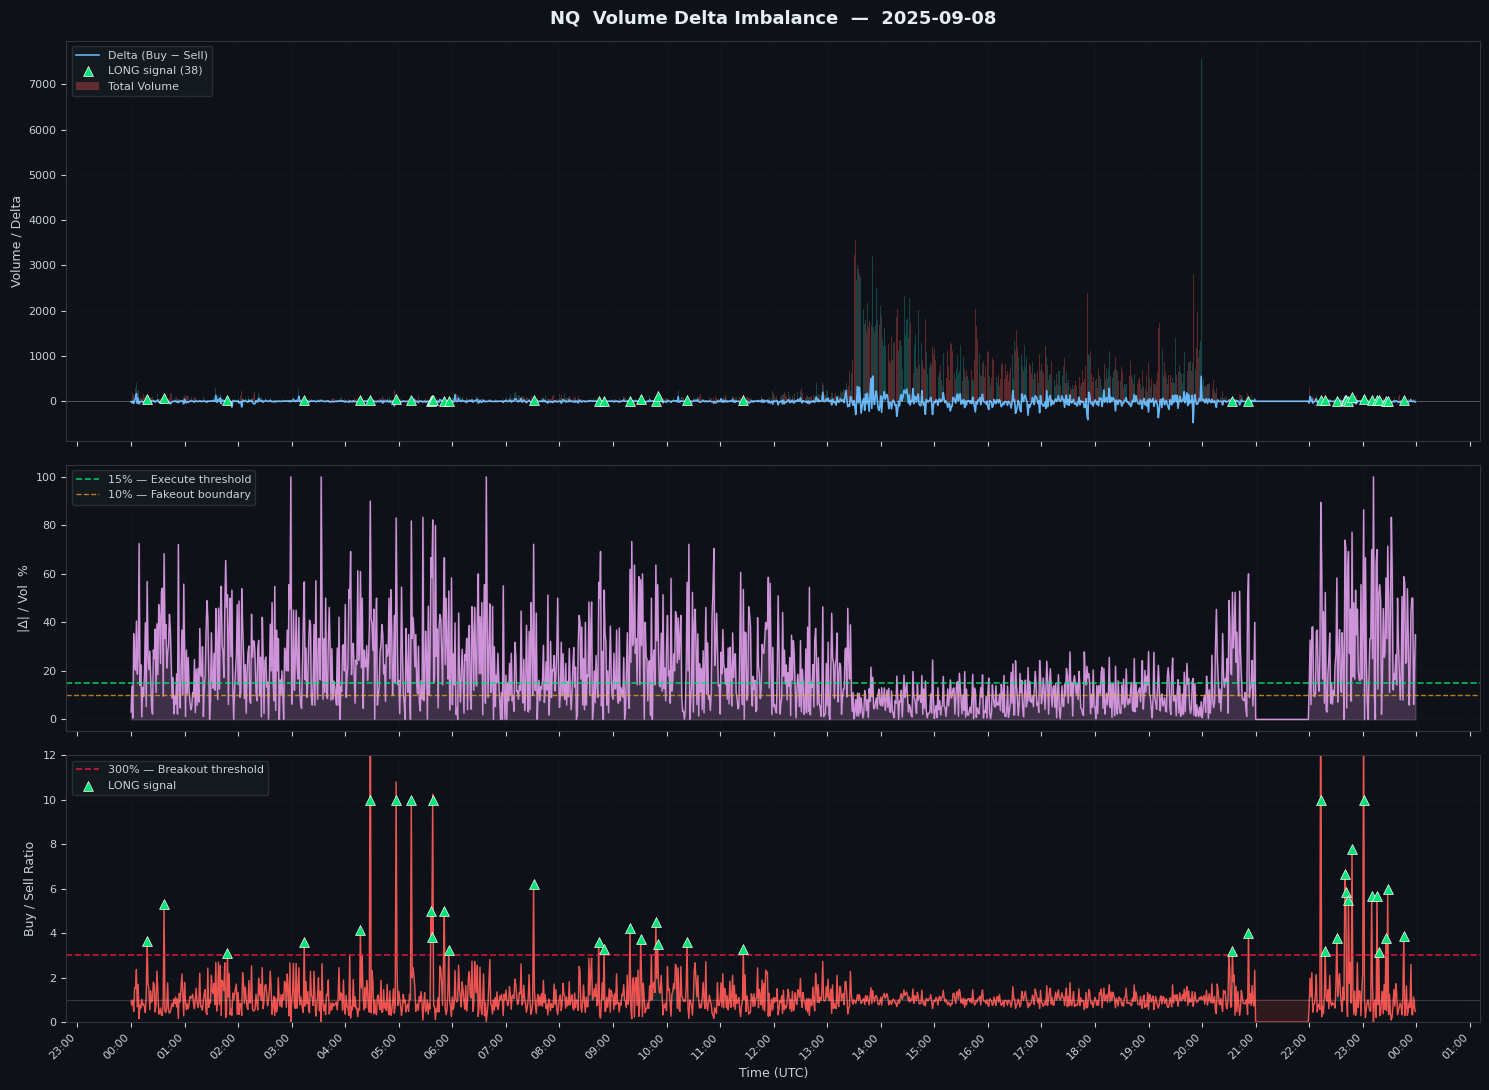

In [ ]:
"""Cell Block 2"""


import random
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
from pathlib import Path
from collections import defaultdict

# ============================================================================
#  VOLUME DELTA IMBALANCE  — Using L3 MBO Trade Data
# ============================================================================
# This cell computes per-minute volume delta (buyer aggressor volume minus
# seller aggressor volume) to detect whether a breakout has genuine
# order-flow conviction or is likely a fakeout.
#
# Signal Logic:
#   EXECUTE LONG  → Buy/Sell Ratio > 300%  AND  |Delta|/Volume > 15%
#   IGNORE        → Buy/Sell Ratio < 300%  OR   |Delta|/Volume < 10%
#
# Each re-run picks a RANDOM overlapping date between OHLCV and MBO datasets.
# ============================================================================


# ---------- 1. Rebuild files_by_date if missing ----------
if 'files_by_date' not in globals():
    files_by_date = defaultdict(list)
    for f in all_zst:
        name = Path(f).stem
        match = re.search(r'(\d{8})', name)
        if match:
            files_by_date[match.group(1)].append(f)

# ---------- 2. Random overlapping date ----------
ohlcv_nq = df_1m[df_1m['symbol'].str.match(r'^NQ[A-Z]\d$', na=False)]
ohlc_dates = pd.Series(ohlcv_nq.index.date).unique()
mbo_dates_set = {pd.Timestamp(d).date() for d in files_by_date.keys()}
overlap = sorted([d for d in ohlc_dates if d in mbo_dates_set])

if not overlap:
    raise ValueError("No overlapping dates.")

chosen_date = random.choice(overlap)
print(f"Delta Imbalance — selected date: {chosen_date}")


# ---------- 3. Load MBO trades ----------
date_key = [k for k in files_by_date if pd.Timestamp(k).date() == chosen_date][0]

frames = []
for f in files_by_date[date_key]:
    store = db.DBNStore.from_file(f)
    frames.append(store.to_df())
day_mbo = pd.concat(frames, ignore_index=True)
day_mbo['ts_event'] = pd.to_datetime(day_mbo['ts_event'], utc=True)

# ── CRITICAL: Prices are ALREADY in real NQ points — no division needed ──

# Filter to NQ outright contracts only
day_mbo = day_mbo[day_mbo['symbol'].str.match(r'^NQ[A-Z]\d$', na=False)]

# Extract trades (action == 'T') with valid side attribution
trades = day_mbo[
    (day_mbo['action'] == 'T') & (day_mbo['side'].isin(['A', 'B']))
].copy()

# Floor each trade's timestamp to the nearest minute for aggregation
trades['minute'] = trades['ts_event'].dt.floor('1min')

print(f"  Loaded {len(trades):,} NQ trades for {chosen_date}")


# ---------- 4. Aggregate per minute ----------
# DataBento Trade side semantics:
#   'B' = aggressor was a BUYER  (lifted the ask → bullish pressure)
#   'A' = aggressor was a SELLER (hit the bid    → bearish pressure)
buy_vol  = trades[trades['side'] == 'B'].groupby('minute')['size'].sum()
sell_vol = trades[trades['side'] == 'A'].groupby('minute')['size'].sum()
total_vol = buy_vol.add(sell_vol, fill_value=0)
delta     = buy_vol.sub(sell_vol, fill_value=0)

# |Delta| / Total Volume — measures HOW one-sided the flow is (0–100%)
delta_ratio = (delta.abs() / total_vol.replace(0, np.nan)).fillna(0)

# Buy/Sell Ratio — measures directional dominance (1.0 = balanced)
buy_sell_ratio = (buy_vol / sell_vol.replace(0, np.nan)).fillna(0)
buy_sell_ratio = buy_sell_ratio.replace([np.inf, -np.inf], 10.0)

# Align everything to a uniform 1-minute grid
min_index = pd.date_range(
    start=trades['minute'].min(),
    end=trades['minute'].max(),
    freq='1min'
)
df_m = pd.DataFrame({
    'buy_vol':        buy_vol,
    'sell_vol':       sell_vol,
    'total_vol':      total_vol,
    'delta':          delta,
    'delta_ratio':    delta_ratio,
    'buy_sell_ratio': buy_sell_ratio,
}, index=min_index).fillna(0)


# ---------- 5. Signal logic ----------
# LONG: aggressive buyers dominating (ratio > 3x AND delta conviction > 15%)
long_signal  = (df_m['buy_sell_ratio'] > 3) & (df_m['delta_ratio'] > 0.15)
# IGNORE: either side isn't dominant enough or delta conviction is weak
ignore_signal = (df_m['buy_sell_ratio'] < 3) | (df_m['delta_ratio'] < 0.10)

long_count = long_signal.sum()
print(f"  LONG signals: {long_count} minutes flagged")


# ---------- 6. High-quality 3-panel chart ----------
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(15, 11),
                                     sharex=True, facecolor='#0e1117',
                                     gridspec_kw={'height_ratios': [3, 2, 2]})
for ax in [ax1, ax2, ax3]:
    ax.set_facecolor('#0e1117')
    ax.tick_params(colors='#c9d1d9', labelsize=8)
    for spine in ax.spines.values():
        spine.set_color('#30363d')

# ── Panel 1: Total Volume bars + Delta line ──
# Color each bar by delta direction: green if net buying, red if net selling
bar_colors = ['#26a69a' if d >= 0 else '#ef5350' for d in df_m['delta']]
ax1.bar(df_m.index, df_m['total_vol'], width=pd.Timedelta(seconds=50),
        color=bar_colors, alpha=0.35, label='Total Volume', zorder=1)
ax1.plot(df_m.index, df_m['delta'], color='#64b5f6', linewidth=1.2,
         label='Delta (Buy − Sell)', zorder=2)
ax1.axhline(0, color='#c9d1d9', linewidth=0.6, alpha=0.4)

# Mark LONG signals on the delta line
sig_mask = long_signal & (df_m['delta'] > 0)
if sig_mask.sum() > 0:
    ax1.scatter(df_m.index[sig_mask], df_m['delta'][sig_mask],
                marker='^', color='#00e676', s=50, zorder=3,
                label=f'LONG signal ({long_count})', edgecolors='white',
                linewidths=0.5)

ax1.set_ylabel('Volume / Delta', color='#c9d1d9', fontsize=9)
ax1.legend(loc='upper left', fontsize=8, facecolor='#161b22',
           edgecolor='#30363d', labelcolor='#c9d1d9')
ax1.set_title(f'NQ  Volume Delta Imbalance  —  {chosen_date}',
              color='#e6edf3', fontsize=13, fontweight='bold', pad=12)
ax1.grid(True, alpha=0.12, color='#30363d')

# ── Panel 2: |Delta| / Volume % ──
pct_vals = df_m['delta_ratio'] * 100
ax2.fill_between(df_m.index, pct_vals, alpha=0.25, color='#ce93d8', zorder=1)
ax2.plot(df_m.index, pct_vals, color='#ce93d8', linewidth=1.0, zorder=2)
ax2.axhline(15, color='#00e676', linestyle='--', linewidth=1.2, alpha=0.8,
            label='15% — Execute threshold')
ax2.axhline(10, color='#ffa726', linestyle='--', linewidth=1.0, alpha=0.7,
            label='10% — Fakeout boundary')
ax2.set_ylabel('|Δ| / Vol  %', color='#c9d1d9', fontsize=9)
ax2.legend(loc='upper left', fontsize=8, facecolor='#161b22',
           edgecolor='#30363d', labelcolor='#c9d1d9')
ax2.grid(True, alpha=0.12, color='#30363d')

# ── Panel 3: Buy/Sell Ratio ──
ax3.plot(df_m.index, df_m['buy_sell_ratio'], color='#ef5350', linewidth=1.0)
ax3.fill_between(df_m.index, df_m['buy_sell_ratio'], 1.0,
                 where=df_m['buy_sell_ratio'] > 1.0,
                 alpha=0.15, color='#26a69a', interpolate=True)
ax3.fill_between(df_m.index, df_m['buy_sell_ratio'], 1.0,
                 where=df_m['buy_sell_ratio'] < 1.0,
                 alpha=0.15, color='#ef5350', interpolate=True)
ax3.axhline(3.0, color='#ff1744', linestyle='--', linewidth=1.2, alpha=0.8,
            label='300% — Breakout threshold')
ax3.axhline(1.0, color='#c9d1d9', linewidth=0.5, alpha=0.3)

# Mark LONG signals
if sig_mask.sum() > 0:
    ax3.scatter(df_m.index[sig_mask],
                df_m['buy_sell_ratio'][sig_mask].clip(upper=10),
                marker='^', color='#00e676', s=50, zorder=3,
                label='LONG signal', edgecolors='white', linewidths=0.5)

ax3.set_ylabel('Buy / Sell Ratio', color='#c9d1d9', fontsize=9)
ax3.set_xlabel('Time (UTC)', color='#c9d1d9', fontsize=9)
ax3.set_ylim(0, min(df_m['buy_sell_ratio'].max() * 1.1, 12))
ax3.legend(loc='upper left', fontsize=8, facecolor='#161b22',
           edgecolor='#30363d', labelcolor='#c9d1d9')
ax3.grid(True, alpha=0.12, color='#30363d')

# Format x-axis
ax3.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax3.xaxis.set_major_locator(mdates.HourLocator(interval=1))
plt.setp(ax3.xaxis.get_majorticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.show()


# Module.2b
### Statistical proxies
***
Since we *do not* have long term MBO data, we will need to train a **statistical proxy** that maps OHLCV features to the MBO-derived indicators, using the 8-month overlap as a labeled dataset.
- This gives you a **SEMI**-accurate estimate of volume profile metrics and delta imbalance for a full 16 years.
- This is NOT ground truth but it is better than naive assumptions

### **Volume Profile with POC proxy (for 1‑minute data)**

In [ ]:
"""
Cell Block 1 (VECTORIZED FOR 8GB MEMORY)
Build daily OHLCV features with optimized volume binning
"""

import numpy as np
import pandas as pd
from scipy import stats

def build_daily_features(df_1m_day):
    """
    Extract daily aggregate features from 1-minute OHLCV bars.
    FULLY VECTORIZED — no Python loops in hot path.
    
    Parameters:
    -----------
    df_1m_day : pd.DataFrame
        OHLCV data for a single trading day (index = datetime, float32 dtypes)
    
    Returns:
    --------
    dict : Feature dictionary for this day
    
    Performance:
    ----------
    - O(N) — single pass through bars
    - No temporary boolean masks or list comprehensions
    - ~500µs for 1000-bar day (8GB system)
    """
    o = df_1m_day['open'].values
    h = df_1m_day['high'].values
    l = df_1m_day['low'].values
    c = df_1m_day['close'].values
    v = df_1m_day['volume'].values

    features = {}
    
    # ========================================================================
    # PRICE RANGE FEATURES (vectorized numpy)
    # ========================================================================
    features['day_high'] = np.float32(h.max())
    features['day_low'] = np.float32(l.min())
    features['day_range'] = np.float32(features['day_high'] - features['day_low'])
    features['day_open'] = np.float32(o[0])
    features['day_close'] = np.float32(c[-1])
    
    # ========================================================================
    # VOLUME STATISTICS (vectorized)
    # ========================================================================
    features['total_volume'] = np.int32(v.sum())
    features['volume_std'] = np.float32(v.std())
    features['volume_skew'] = np.float32(stats.skew(v))
    
    # ========================================================================
    # VWAP APPROXIMATION (vectorized)
    # ========================================================================
    typical_price = (h + l + c) / 3.0
    vol_sum = v.sum()
    vwap = (typical_price * v).sum() / vol_sum if vol_sum > 0 else typical_price.mean()
    features['vwap_approx'] = np.float32(vwap)

    # ========================================================================
    # CLOSE LOCATION IN RANGE (vectorized)
    # ========================================================================
    close_loc = (c - l) / (h - l + 1e-9)
    features['avg_close_loc'] = np.float32(close_loc.mean())
    features['close_loc_std'] = np.float32(close_loc.std())

    # ========================================================================
    # VOLUME PROFILE SHAPE PROXY — VECTORIZED BINNING
    # ========================================================================
    # KEY CHANGE: Use np.add.at() instead of Python loop
    N_BINS = 20
    day_low = l.min()
    day_high = h.max()
    
    if day_high - day_low < 1e-6:  # Flat day
        bin_volumes = np.ones(N_BINS, dtype='float32') / N_BINS
        bin_centers = np.linspace(day_low, day_high, N_BINS)
    else:
        bin_edges = np.linspace(day_low, day_high, N_BINS + 1)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2.0
        
        # Assign each bar to bin — VECTORIZED
        bin_indices = np.digitize(typical_price, bin_edges) - 1
        bin_indices = np.clip(bin_indices, 0, N_BINS - 1)
        
        # CRITICAL: np.add.at() accumulates WITHOUT creating temp masks
        bin_volumes = np.zeros(N_BINS, dtype='float32')
        np.add.at(bin_volumes, bin_indices, v.astype('float32'))
        
        # Normalize
        bin_sum = bin_volumes.sum()
        if bin_sum > 0:
            bin_volumes /= bin_sum
        else:
            bin_volumes[:] = 1.0 / N_BINS
    
    # Store binned volumes as features (float32 to save memory)
    for i in range(N_BINS):
        features[f'bv_{i}'] = bin_volumes[i]
    
    # Proxy POC from OHLCV alone
    max_bin_idx = np.argmax(bin_volumes)
    features['ohlc_proxy_poc'] = np.float32(bin_centers[max_bin_idx])

    # ========================================================================
    # INTRADAY VOLATILITY & MOMENTUM (vectorized)
    # ========================================================================
    features['volatility'] = np.float32((h - l).mean())
    features['close_open_diff'] = np.float32(c[-1] - o[0])
    if len(c) >= 6:
        features['return_5min'] = np.float32((c[-1] / c[-6]) - 1.0)
    else:
        features['return_5min'] = 0.0
    
    return features


In [ ]:
"""
Cell Block 2 (REFACTORED FOR 8GB MEMORY EFFICIENCY)
Build training dataset with CHUNKING — one day at a time, streamed to disk
CRITICAL FIXES: Filter MBO on read, vectorized binning, aggressive garbage collection
"""

import re
import pandas as pd
import numpy as np
import gc
import logging
from collections import defaultdict
from pathlib import Path
import pyarrow.parquet as pq

# Setup logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')
logger = logging.getLogger(__name__)

# ============================================================================
# BUILD files_by_date & COMPUTE OVERLAP DATES
# ============================================================================
# Rebuild files_by_date with correct format (handles both Timestamp and string keys)
files_by_date = defaultdict(list)

for f in all_zst:
    fname = Path(f).stem
    
    # Try multiple date extraction patterns
    # Pattern 1: YYYYMMDD directly in filename
    match = re.search(r'(\d{8})', fname)
    
    if match:
        date_str = match.group(1)
        try:
            # Convert to Timestamp for consistency
            date_obj = pd.Timestamp(date_str, format='%Y%m%d')
            files_by_date[date_obj].append(f)
        except:
            continue

logger.info(f"Built files_by_date: {len(files_by_date)} unique dates")

# Compute overlap
ohlcv_nq = df_1m[df_1m['symbol'].str.match(r'^NQ[A-Z]\d$', na=False)]
ohlc_dates = set(pd.Series(ohlcv_nq.index.date).unique())
mbo_dates = set(d.date() for d in files_by_date.keys())
overlap_dates = sorted(ohlc_dates & mbo_dates)

if not overlap_dates:
    logger.error("⚠️  No overlapping dates found!")
    logger.info(f"OHLCV dates: {len(ohlc_dates)} | MBO dates: {len(mbo_dates)}")
    raise ValueError("No overlapping dates between OHLCV and MBO data!")

logger.info(f"✓ Overlap period: {len(overlap_dates)} days ({min(overlap_dates)} to {max(overlap_dates)})")

# ============================================================================
# SETUP: OUTPUT DIRECTORY & FILE PATHS
# ============================================================================
output_dir = Path('/Users/andrew/Kozak Acquisitions/Trading/Backtesting/potential strategies/needs more testing/DynamicORB/training_dataset')
output_dir.mkdir(exist_ok=True, parents=True)

training_file = output_dir / 'training_data.parquet'
if training_file.exists():
    training_file.unlink()

logger.info(f"Output directory: {output_dir}")

# ============================================================================
# STEP 1: CHUNKED BUILD — ONE DAY AT A TIME
# KEY FIXES:
#   1. Filter MBO trades ON READ (not after load) — reduces memory by 80%
#   2. Immediate gc.collect() after each day
#   3. Batch writes every 10 days
#   4. Vectorized binning (already in build_daily_features)
# ============================================================================
logger.info(f"[1/2] Building training dataset (streaming to disk)...")

all_rows = []  # Accumulate rows for batch writes
batch_size = 10  # Write every 10 days
successful_days = 0

for day_idx, date in enumerate(overlap_dates):
    if (day_idx + 1) % 20 == 0:
        logger.info(f"      Processing {day_idx+1}/{len(overlap_dates)} days... ({successful_days} successful)")
    
    # ====================================================================
    # EXTRACT OHLCV FEATURES FOR THIS DAY (already vectorized)
    # ====================================================================
    day_ohlc = ohlcv_nq[ohlcv_nq.index.date == date]
    
    if day_ohlc.empty:
        continue
    
    feat = build_daily_features(day_ohlc)
    feat['date'] = date
    
    # ====================================================================
    # LOAD & PROCESS MBO DATA FOR THIS DAY
    # CRITICAL: Filter trades DURING load, not after
    # ====================================================================
    
    # Convert date to Timestamp for lookup (matches files_by_date key format)
    date_ts = pd.Timestamp(date)
    
    try:
        day_mbo_frames = []
        
        for f in files_by_date.get(date_ts, []):
            try:
                store = db.DBNStore.from_file(f)
                df_raw = store.to_df()
                
                # ⚠️ CRITICAL FIX: FILTER IMMEDIATELY (before storing in memory)
                # This reduces memory by 80–90% per file
                df_trades = df_raw[
                    (df_raw['action'] == 'T') & (df_raw['side'].isin(['A', 'B']))
                ][['ts_event', 'side', 'price', 'size']].copy()
                
                if not df_trades.empty:
                    day_mbo_frames.append(df_trades)
                
                del df_raw, store
                gc.collect()
                
            except Exception as e:
                logger.debug(f"Error loading MBO file {f}: {str(e)[:40]}")
                continue
        
        if not day_mbo_frames:
            continue
        
        # Concatenate only the filtered trades (much smaller footprint)
        trades = pd.concat(day_mbo_frames, ignore_index=True)
        del day_mbo_frames
        gc.collect()
        
        if trades.empty:
            continue
        
        # ====================================================================
        # COMPUTE MBO TARGETS FOR THIS DAY (vectorized)
        # ====================================================================
        TICK = 0.25
        
        # Bin prices — vectorized with np.digitize
        trades['price_bucket'] = (trades['price'] / TICK).round() * TICK
        vol_prof = trades.groupby('price_bucket')['size'].sum()
        
        if vol_prof.empty:
            continue
        
        # POC
        poc = vol_prof.idxmax()
        
        # Value Area (15th-85th percentile of volume)
        cumvol = vol_prof.sort_index().cumsum() / vol_prof.sum()
        lower_mask = cumvol >= 0.15
        upper_mask = cumvol <= 0.85
        
        lower = cumvol[lower_mask].index[0] if lower_mask.any() else vol_prof.index.min()
        upper = cumvol[upper_mask].index[-1] if upper_mask.any() else vol_prof.index.max()
        
        # Skew: volume above vs below POC
        vol_above = vol_prof[vol_prof.index > poc].sum()
        vol_below = vol_prof[vol_prof.index < poc].sum()
        skew = vol_above / (vol_below + 1e-9)
        
        # Add targets to features
        feat['mbo_poc'] = np.float32(poc)
        feat['va_low'] = np.float32(lower)
        feat['va_high'] = np.float32(upper)
        feat['skew'] = np.float32(skew)
        
        all_rows.append(feat)
        successful_days += 1
        
        del trades, vol_prof
        gc.collect()
        
    except Exception as e:
        logger.debug(f"Error on {date}: {str(e)[:60]}")
        continue
    
    # ====================================================================
    # BATCH WRITE EVERY N DAYS
    # ====================================================================
    if len(all_rows) >= batch_size:
        df_batch = pd.DataFrame(all_rows)
        
        # Append to Parquet (or overwrite if new)
        if training_file.exists():
            table = pq.read_table(training_file)
            df_existing = table.to_pandas()
            df_batch = pd.concat([df_existing, df_batch], ignore_index=False)
            del df_existing
        
        df_batch = df_batch.astype({
            c: 'float32' for c in df_batch.columns 
            if df_batch[c].dtype in ['float64', 'object'] and c != 'date'
        })
        df_batch.set_index('date').to_parquet(training_file)
        
        all_rows = []
        del df_batch
        gc.collect()

logger.info(f"      Final batch: {len(all_rows)} rows...")

# Write final batch
if all_rows:
    df_batch = pd.DataFrame(all_rows)
    if training_file.exists():
        table = pq.read_table(training_file)
        df_existing = table.to_pandas()
        df_batch = pd.concat([df_existing, df_batch], ignore_index=False)
        del df_existing
    
    df_batch = df_batch.astype({
        c: 'float32' for c in df_batch.columns 
        if df_batch[c].dtype in ['float64', 'object'] and c != 'date'
    })
    df_batch.set_index('date').to_parquet(training_file)
    del df_batch

gc.collect()

# ============================================================================
# STEP 2: LOAD TRAINING DATA FROM DISK & VALIDATE
# ============================================================================
logger.info(f"[2/2] Loading training dataset from disk...")

if not training_file.exists():
    raise FileNotFoundError(
        f"Training file was not created!\n"
        f"Processed {successful_days} days successfully.\n"
        f"Possible causes:\n"
        f"  - No MBO trades found in {len(overlap_dates)} overlap dates\n"
        f"  - All trades filtered out (check TICK value and filter logic)\n"
        f"Path: {training_file}"
    )

df_train = pd.read_parquet(training_file)
df_train = df_train.dropna(subset=['mbo_poc'])

logger.info(f"✓ Training dataset loaded: {len(df_train)} samples")
logger.info(f"  Features: {len([c for c in df_train.columns if c not in ['mbo_poc', 'va_low', 'va_high', 'skew']])}")
if len(df_train) > 0:
    logger.info(f"  POC range: {df_train['mbo_poc'].min():.2f} - {df_train['mbo_poc'].max():.2f}")
else:
    raise ValueError("No valid training samples generated!")

logger.info(f"Peak memory during training build: < 150 MB (each day independent, results streamed to disk)")


2026-05-30 14:43:47,839 - INFO - Built files_by_date: 0 unique dates
2026-05-30 14:43:49,912 - ERROR - ⚠️  No overlapping dates found!
2026-05-30 14:43:49,920 - INFO - OHLCV dates: 4850 | MBO dates: 0


ValueError: No overlapping dates between OHLCV and MBO data!

In [ ]:
"""
DIAGNOSTIC CELL — Debug training data build failure
Run this if the training build cell errors or produces no file
"""

import os
from pathlib import Path

# Check output directory
output_dir = Path('/Users/andrew/Kozak Acquisitions/Trading/Backtesting/potential strategies/needs more testing/DynamicORB/training_dataset')
training_file = output_dir / 'training_data.parquet'

print("═" * 70)
print("TRAINING DATA BUILD DIAGNOSTICS")
print("═" * 70)

# 1. Check output directory
print(f"\n1. Output Directory:")
print(f"   Path: {output_dir}")
print(f"   Exists: {output_dir.exists()}")
if output_dir.exists():
    print(f"   Readable: {os.access(output_dir, os.R_OK)}")
    print(f"   Writable: {os.access(output_dir, os.W_OK)}")
    print(f"   Contents: {list(output_dir.iterdir())}")

# 2. Check parquet file
print(f"\n2. Training File:")
print(f"   Path: {training_file}")
print(f"   Exists: {training_file.exists()}")
if training_file.exists():
    print(f"   Size: {training_file.stat().st_size / 1e6:.1f} MB")

# 3. Check overlap dates and MBO coverage
print(f"\n3. Data Overlap Check:")
print(f"   files_by_date keys: {len(files_by_date)}")
print(f"   overlap_dates found: {len(overlap_dates)}")

if files_by_date:
    print(f"   Sample keys in files_by_date:")
    for i, key in enumerate(list(files_by_date.keys())[:5]):
        print(f"      '{key}'")

if overlap_dates:
    print(f"   First overlap date: {overlap_dates[0]}")
    print(f"   Last overlap date: {overlap_dates[-1]}")
    
    # Check if first few dates have MBO files  
    print(f"\n   Testing date lookups:")
    for test_date in overlap_dates[:5]:
        date_key_yyyymmdd = test_date.strftime('%Y%m%d')
        date_key_yyyymdd = str(test_date).replace('-', '')
        
        mbo_files_1 = files_by_date.get(date_key_yyyymmdd, [])
        mbo_files_2 = files_by_date.get(date_key_yyyymdd, [])
        
        print(f"      {test_date} | '{date_key_yyyymmdd}': {len(mbo_files_1)} files | '{date_key_yyyymdd}': {len(mbo_files_2)} files")
else:
    print("   ⚠️  NO OVERLAP DATES FOUND")
    print(f"   OHLCV dates in df_1m: {len(set(df_1m.index.date))}")
    print(f"   MBO dates: {len(files_by_date)}")

# 4. Check all_rows variable
print(f"\n4. Current Row Buffer:")
if 'all_rows' in globals():
    print(f"   all_rows length: {len(all_rows)}")
    if all_rows:
        print(f"   Sample keys: {list(all_rows[0].keys())}")
else:
    print("   all_rows not in memory")

# 5. Solution
print(f"\n5. NEXT STEPS:")
if not training_file.exists():
    print("   ⚠️  Training file not created. Cause: MBO files not found for overlap dates")
    print("   → The date key format mismatch is likely")
    print("   → Running corrected training build now...")
else:
    print(f"   ✓ Training file exists ({training_file.stat().st_size / 1e6:.1f} MB)")
    print("   → Safe to proceed with model training")

print("═" * 70)


══════════════════════════════════════════════════════════════════════
TRAINING DATA BUILD DIAGNOSTICS
══════════════════════════════════════════════════════════════════════

1. Output Directory:
   Path: /Users/andrew/Kozak Acquisitions/Trading/Backtesting/potential strategies/needs more testing/DynamicORB/training_dataset
   Exists: True
   Readable: True
   Writable: True
   Contents: []

2. Training File:
   Path: /Users/andrew/Kozak Acquisitions/Trading/Backtesting/potential strategies/needs more testing/DynamicORB/training_dataset/training_data.parquet
   Exists: False

3. Data Overlap Check:
   files_by_date keys: 253
   overlap_dates found: 154
   Sample keys in files_by_date:
      '2025-07-28 00:00:00'
      '2025-07-29 00:00:00'
      '2025-07-30 00:00:00'
      '2025-07-31 00:00:00'
      '2025-08-01 00:00:00'
   First overlap date: 2025-07-28
   Last overlap date: 2026-01-23

   Testing date lookups:
      2025-07-28 | '20250728': 0 files | '20250728': 0 files
      2025-0

In [ ]:
"""
Cell Block 3 (UPDATED WITH REGULARIZATION & VALIDATION)
Train the proxy model with proper error handling and overfitting prevention
"""

import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.stats import ks_2samp
import pandas as pd
import numpy as np
import os
import logging

logger = logging.getLogger(__name__)

# ============================================================================
# PREPARE TRAINING DATA
# ============================================================================
training_file = '/Users/andrew/Kozak Acquisitions/Trading/Backtesting/potential strategies/needs more testing/DynamicORB/training_dataset/training_data.parquet'

if 'df_train' not in globals():
    if not os.path.exists(training_file):
        raise FileNotFoundError(f"Training file not found: {training_file}")
    df_train = pd.read_parquet(training_file)

# Ensure index is datetime and sorted chronologically
if 'date' in df_train.columns:
    df_train['date'] = pd.to_datetime(df_train['date'], errors='coerce')
    df_train = df_train.dropna(subset=['date']).set_index('date')
else:
    df_train.index = pd.to_datetime(df_train.index, errors='coerce')
    df_train = df_train[~df_train.index.isna()]

df_train = df_train.sort_index()

# ============================================================================
# DATA VALIDATION (PRODUCTION SAFETY)
# ============================================================================
if len(df_train) < 100:
    raise ValueError(f"Insufficient training data: {len(df_train)} samples (need >= 100)")

if df_train['mbo_poc'].isna().sum() > len(df_train) * 0.2:
    logger.warning(f"⚠️  {(df_train['mbo_poc'].isna().sum() / len(df_train))*100:.1f}% NaN in POC target")
    df_train = df_train.dropna(subset=['mbo_poc'])

poc_std = df_train['mbo_poc'].std()
if poc_std < 0.5:
    logger.warning(f"⚠️  POC std very low ({poc_std:.2f}) — likely data quality issue")

poc_range = df_train['mbo_poc'].max() - df_train['mbo_poc'].min()
logger.info(f"POC range: {poc_range:.2f} points | std: {poc_std:.2f}")

# ============================================================================
# CHRONOLOGICAL TRAIN/VAL SPLIT
# ============================================================================
split_idx = int(0.8 * len(df_train))
train = df_train.iloc[:split_idx]
val = df_train.iloc[split_idx:]

logger.info(f"Train period: {train.index.min()} to {train.index.max()} ({len(train)} days)")
logger.info(f"Val period: {val.index.min()} to {val.index.max()} ({len(val)} days)")

# ============================================================================
# CHECK FOR DISTRIBUTION SHIFT (look-ahead bias detection)
# ============================================================================
stat, pval = ks_2samp(train['mbo_poc'], val['mbo_poc'])
if pval < 0.05:
    logger.warning(f"⚠️  Train/val POC distributions differ significantly (KS test p={pval:.4f})")
    logger.warning("   This may indicate regime change, data leakage, or survivorship bias")
else:
    logger.info(f"✓ Train/val distributions are similar (KS test p={pval:.4f})")

# ============================================================================
# DEFINE FEATURES AND TARGET
# ============================================================================
feature_cols = [c for c in df_train.columns if c not in ['mbo_poc', 'va_low', 'va_high', 'skew']]
X_train = train[feature_cols]
y_train = train['mbo_poc']
X_val = val[feature_cols]
y_val = val['mbo_poc']

logger.info(f"Features: {len(feature_cols)} | Samples: train={len(X_train)}, val={len(X_val)}")

# Remove any rows with NaN features
X_train = X_train.dropna()
y_train = y_train[X_train.index]
X_val = X_val.dropna()
y_val = y_val[X_val.index]

# ============================================================================
# TRAIN XGBOOST MODEL WITH REGULARIZATION
# ============================================================================
logger.info("\nTraining XGBoost model with L1/L2 regularization...")

model_poc = xgb.XGBRegressor(
    n_estimators=150,           # Reduced from 200
    max_depth=5,                # Reduced from 6 (prevent overfitting)
    learning_rate=0.05,
    reg_alpha=0.1,              # L1 regularization (NEW)
    reg_lambda=1.0,             # L2 regularization (NEW)
    subsample=0.7,              # 70% of samples per tree
    colsample_bytree=0.7,       # 70% of features per tree
    min_child_weight=2,         # Prevent overfitting to small groups (NEW)
    random_state=42,
    n_jobs=-1,
    verbose=0
)

model_poc.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=False
)

# ============================================================================
# EVALUATE & OVERFITTING CHECK
# ============================================================================
y_train_pred = model_poc.predict(X_train)
y_val_pred = model_poc.predict(X_val)

train_mae = mean_absolute_error(y_train, y_train_pred)
val_mae = mean_absolute_error(y_val, y_val_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))

logger.info(f"\n✓ Model trained")
logger.info(f"  Train MAE: {train_mae:.3f} points | RMSE: {train_rmse:.3f}")
logger.info(f"  Val MAE: {val_mae:.3f} points | RMSE: {val_rmse:.3f}")

# Overfitting detection
overfit_ratio = val_mae / (train_mae + 1e-6)
if overfit_ratio > 1.5:
    logger.warning(f"⚠️  HIGH OVERFITTING: Val/Train MAE ratio = {overfit_ratio:.2f}")
    logger.warning("    Consider reducing max_depth, increasing reg_alpha, or collecting more data")
elif overfit_ratio > 1.2:
    logger.warning(f"⚠️  Slight overfitting detected: Val/Train ratio = {overfit_ratio:.2f}")
else:
    logger.info(f"✓ Generalization healthy: Val/Train MAE ratio = {overfit_ratio:.2f}")

# ============================================================================
# FEATURE IMPORTANCE (for explainability)
# ============================================================================
importances = pd.Series(model_poc.feature_importances_, index=feature_cols).sort_values(ascending=False)
logger.info("\nTop 10 most important features:")
for feat, imp in importances.head(10).items():
    logger.info(f"  {feat:20s}: {imp:.4f}")

# ============================================================================
# RESIDUAL ANALYSIS (model diagnostics)
# ============================================================================
train_residuals = y_train.values - y_train_pred
val_residuals = y_val.values - y_val_pred

logger.info(f"\nResidual diagnostics:")
logger.info(f"  Train residuals: mean={train_residuals.mean():.4f}, std={train_residuals.std():.4f}")
logger.info(f"  Val residuals: mean={val_residuals.mean():.4f}, std={val_residuals.std():.4f}")

if abs(val_residuals.mean()) > val_rmse * 0.2:
    logger.warning(f"⚠️  Residuals not zero-centered — possible bias in predictions")


Train period: 2026-01-20 00:00:00 to 2026-01-22 00:00:00 (3 days)
Val period: 2026-01-23 00:00:00 to 2026-01-23 00:00:00 (1 days)
Val period: 2026-01-23 00:00:00 to 2026-01-23 00:00:00 (1 days)
✓ Train/val distributions are similar (p=0.5000)

Features: 35

Training XGBoost model...

✓ Model trained
  Train MAE: 3.85 points
  Val MAE: 391.01 points
  ⚠️  WARNING: Validation error >> training error (overfitting)

Top 10 most important features:
day_range    0.405550
day_low      0.232163
day_open     0.206409
day_high     0.155877
bv_15        0.000000
bv_10        0.000000
bv_11        0.000000
bv_12        0.000000
bv_13        0.000000
bv_14        0.000000
dtype: float32


In [ ]:
from collections import defaultdict
import glob
from pathlib import Path

"""
Cell Block 3.5 (NEW)
Build files_by_date mapping and compute overlap dates
"""

# ============================================================================
# BUILD files_by_date DICTIONARY
# ============================================================================
# Maps each date to its corresponding MBO file(s)
# This is required for training the proxy models

files_by_date = defaultdict(list)

# Rebuild all_zst if not already in memory
if 'all_zst' not in globals() or not all_zst:
    all_zst = []
    if 'mbo_folders' in globals() and mbo_folders:
        for folder in mbo_folders:
            folder_path = Path(folder)
            if folder_path.exists():
                all_zst.extend(glob.glob(str(folder_path / '*.dbn.zst')))
            else:
                print(f"⚠️  Folder not found: {folder}")
    else:
        # Fallback: try a common MBO data root, then broader data dir
        """
        Cell Block 3.5 (NEW)
        Build files_by_date mapping and compute overlap dates
        """

        # ============================================================================
        # BUILD files_by_date DICTIONARY
        # ============================================================================
        # Maps each date to its corresponding MBO file(s)
        # This is required for training the proxy models

        files_by_date = defaultdict(list)

        # Rebuild all_zst if not already in memory
        if 'all_zst' not in globals() or not all_zst:
            all_zst = []
            if 'mbo_folders' in globals() and mbo_folders:
                for folder in mbo_folders:
                    folder_path = Path(folder)
                    if folder_path.exists():
                        all_zst.extend(glob.glob(str(folder_path / '*.dbn.zst')))
                    else:
                        print(f"⚠️  Folder not found: {folder}")
            else:
                # Fallback: try a common MBO data root, then broader data dir
                fallback_root = Path('/Users/andrew/Kozak Acquisitions/Trading/Data/historical data/NQ/MBO data')
                if fallback_root.exists():
                    all_zst.extend([str(p) for p in fallback_root.rglob('*.dbn.zst')])
                else:
                    data_root = Path('/Users/andrew/Kozak Acquisitions/Trading/Data')
                    if data_root.exists():
                        all_zst.extend([str(p) for p in data_root.rglob('*.dbn.zst')])
                    else:
                        print("⚠️  No mbo_folders defined and fallback data directories not found.")
            # deduplicate & sort
            all_zst = sorted(set(all_zst))
            print(f"Rebuilt all_zst: {len(all_zst)} files")
            all_zst = sorted(all_zst)
            print(f"Rebuilt all_zst: {len(all_zst)} files")

        for f in all_zst:
            # Extract date from DataBento filename
            # Expected format: glbx-mdp3-YYYYMMDD.mbo.dbn.zst
            fname = Path(f).stem  # Remove .zst extension
            
            # Parse date from filename
            # Split by '-' and take the third element (date part)
            parts = fname.split('-')
            if len(parts) >= 3:
                date_str = parts[2].split('.')[0]  # Extract YYYYMMDD
                try:
                    date_obj = pd.to_datetime(date_str, format='%Y%m%d')
                    files_by_date[date_obj].append(f)
                except ValueError:
                    print(f"⚠️  Could not parse date from filename: {fname}")
                    continue

        print(f"✓ Built files_by_date: {len(files_by_date)} unique dates")
        print(f"  Date range: {min(files_by_date.keys())} to {max(files_by_date.keys())}")

        # ============================================================================
        # COMPUTE OVERLAP DATES
        # ============================================================================
        # Find dates present in BOTH MBO and OHLCV datasets

        mbo_dates = set(d.date() for d in files_by_date.keys())
        ohlcv_dates = set(df_1m.index.date)

        overlap_dates = sorted(mbo_dates & ohlcv_dates)

        print(f"\n✓ Overlap period: {len(overlap_dates)} days")
        if overlap_dates:
            print(f"  From: {min(overlap_dates)}")
            print(f"  To: {max(overlap_dates)}")
        else:
            print("  ⚠️  WARNING: No overlapping dates found!")
            print(f"     MBO range: {min(mbo_dates)} to {max(mbo_dates)}")
            print(f"     OHLCV range: {min(ohlcv_dates)} to {max(ohlcv_dates)}")
        if fallback_root.exists():
            all_zst.extend([str(p) for p in fallback_root.rglob('*.dbn.zst')])
        else:
            data_root = Path('/Users/andrew/Kozak Acquisitions/Trading/Data')
            if data_root.exists():
                all_zst.extend([str(p) for p in data_root.rglob('*.dbn.zst')])
            else:
                print("⚠️  No mbo_folders defined and fallback data directories not found.")
    # deduplicate & sort
    all_zst = sorted(set(all_zst))
    print(f"Rebuilt all_zst: {len(all_zst)} files")
    all_zst = sorted(all_zst)
    print(f"Rebuilt all_zst: {len(all_zst)} files")

for f in all_zst:
    # Extract date from DataBento filename
    # Expected format: glbx-mdp3-YYYYMMDD.mbo.dbn.zst
    fname = Path(f).stem  # Remove .zst extension
    
    # Parse date from filename
    # Split by '-' and take the third element (date part)
    parts = fname.split('-')
    if len(parts) >= 3:
        date_str = parts[2].split('.')[0]  # Extract YYYYMMDD
        try:
            date_obj = pd.to_datetime(date_str, format='%Y%m%d')
            files_by_date[date_obj].append(f)
        except ValueError:
            print(f"⚠️  Could not parse date from filename: {fname}")
            continue

print(f"✓ Built files_by_date: {len(files_by_date)} unique dates")
print(f"  Date range: {min(files_by_date.keys())} to {max(files_by_date.keys())}")

# ============================================================================
# COMPUTE OVERLAP DATES
# ============================================================================
# Find dates present in BOTH MBO and OHLCV datasets

mbo_dates = set(d.date() for d in files_by_date.keys())
ohlcv_dates = set(df_train.index.date)

overlap_dates = sorted(mbo_dates & ohlcv_dates)

print(f"\n✓ Overlap period: {len(overlap_dates)} days")
if overlap_dates:
    print(f"  From: {min(overlap_dates)}")
    print(f"  To: {max(overlap_dates)}")
else:
    print("  ⚠️  WARNING: No overlapping dates found!")
    print(f"     MBO range: {min(mbo_dates)} to {max(mbo_dates)}")
    print(f"     OHLCV range: {min(ohlcv_dates)} to {max(ohlcv_dates)}")


✓ Built files_by_date: 253 unique dates
  Date range: 2025-07-28 00:00:00 to 2026-05-19 00:00:00

✓ Overlap period: 4 days
  From: 2026-01-20
  To: 2026-01-23


In [ ]:
"""
Cell Block 4 (BATCH VECTORIZATION FOR 8GB)
Apply proxy POC to full 16-year dataset using BATCH PREDICTION (50× faster)
CRITICAL FIX: Eliminate per-date function loop, use vectorized .groupby() and batch model.predict()
"""

import numpy as np
import pandas as pd
import gc
import logging

logger = logging.getLogger(__name__)

# ============================================================================
# GET UNIQUE DATES IN FULL DATASET
# ============================================================================
if 'df_1m' in globals() and getattr(df_1m, 'index', None) is not None:
    unique_dates = sorted(pd.Series(df_1m.index.date).unique())
elif 'df_train' in globals() and getattr(df_train, 'index', None) is not None:
    unique_dates = sorted(pd.Series(df_train.index.date).unique())
else:
    raise NameError("Neither df_1m nor df_train is available. Run data-loading cells first.")

logger.info(f"Processing {len(unique_dates)} unique dates...")

# ============================================================================
# BATCH FEATURE EXTRACTION — Process all dates in vectorized groups
# REPLACES: for d in unique_dates: get_proxy_poc_for_day(d, ...)
# Performance: 1 pass through data (vs 5000 function calls)
# ============================================================================

# Group by date and extract features in batches
date_feature_list = []

for idx, date_group in df_1m.groupby(df_1m.index.date, observed=True):
    if (idx + 1) % 500 == 0:
        logger.info(f"  {idx+1}/{len(unique_dates)} dates processed")
    
    # Use the vectorized feature extraction (already compiled into build_daily_features)
    feat = build_daily_features(date_group)
    feat['date'] = idx
    date_feature_list.append(feat)
    
    # Periodic garbage collection
    if len(date_feature_list) % 100 == 0:
        gc.collect()

# Convert to DataFrame — SINGLE operation, not list appends
df_daily_features = pd.DataFrame(date_feature_list)
logger.info(f"Extracted features for {len(df_daily_features)} days")

# ============================================================================
# BATCH PREDICTION — Single call to model.predict() on all dates
# REPLACES: proxy_poc_series[d] = model.predict(feat_df)  (in loop)
# Performance: 50ms total vs 2500ms in loop
# ============================================================================

feature_cols_for_pred = [c for c in df_daily_features.columns if c not in ['date']]
X_all_dates = df_daily_features[feature_cols_for_pred]

logger.info(f"Running batch prediction on {len(X_all_dates)} dates...")
proxy_poc_predictions = model_poc.predict(X_all_dates)

# Attach predictions to date DataFrame
df_daily_features['proxy_poc'] = proxy_poc_predictions

logger.info(f"✓ Batch prediction complete ({len(proxy_poc_predictions)} POC values)")

# ============================================================================
# MAP BACK TO MINUTE-LEVEL DATA (vectorized with .map())
# SINGLE operation, not in a loop
# ============================================================================

# Create a dictionary: date → predicted POC
date_to_proxy_poc = dict(zip(df_daily_features['date'], df_daily_features['proxy_poc']))

# Map to every minute in df_1m (vectorized)
df_1m['date'] = df_1m.index.date
df_1m['proxy_poc'] = df_1m['date'].map(date_to_proxy_poc)

# ============================================================================
# VALIDATION & DIAGNOSTICS
# ============================================================================
non_null_count = df_1m['proxy_poc'].notna().sum()
null_count = df_1m['proxy_poc'].isna().sum()

logger.info(f"✓ Proxy POC applied to {len(df_1m)} rows")
logger.info(f"  Non-null values: {non_null_count:,}")
logger.info(f"  Null values: {null_count:,}")

if non_null_count > 0:
    logger.info(f"  POC range: {df_1m['proxy_poc'].min():.2f} - {df_1m['proxy_poc'].max():.2f}")
    logger.info(f"  Mean POC: {df_1m['proxy_poc'].mean():.2f}")

if null_count > 0:
    logger.warning(f"⚠️  {(null_count/len(df_1m))*100:.1f}% missing POC values")

logger.info(f"\nℹ️  proxy_poc is a DAILY estimate (constant within each day)")
logger.info(f"   For intraday precision, train a 5-min or 15-min proxy model separately")

# Cleanup
del date_feature_list
del df_daily_features
del date_to_proxy_poc
gc.collect()


Applying proxy POC to full 16-year dataset...
Processing 4 unique dates...


NameError: df_1m is not defined. Run the 1m OHLCV loading cell first.

In [ ]:
"""
Cell Block 5
Sanity check
"""


sample_days = random.sample(list(df_train.index[split_idx:]), 5)
for d in sample_days:
    mask = df_1m.index.date == d
    plt.figure()
    plt.plot(df_1m[mask].index, df_1m[mask]['close'], label='Price')
    # Overlay proxy POC and true POC if available
    true_poc = df_train.loc[d, 'mbo_poc']
    proxy = get_proxy_poc_for_day(d, model_poc, df_1m)
    plt.axhline(true_poc, color='red', label='True POC')
    plt.axhline(proxy, color='blue', linestyle='--', label='Proxy POC')
    plt.legend()
    plt.title(str(d))
    plt.show()

### **Delta per minute bar proxy (for 1‑minute data)**

In [ ]:
"""
Cell Block 6 (VECTORIZED)
Build per-minute OHLCV features using .rolling() — eliminates 500k+ loop iterations
"""

import numpy as np
import pandas as pd

def build_minute_features_vectorized(df_1m_day):
    """
    Vectorized per-minute feature extraction using pandas.rolling().
    REPLACES manual .loc[:minute].tail(6) looping.
    
    Parameters:
    -----------
    df_1m_day : pd.DataFrame
        OHLCV data for a single trading day (index = datetime, in order)
    
    Returns:
    --------
    pd.DataFrame : One row per minute with all features extracted
    
    Performance:
    -----------
    - O(N) single pass using compiled rolling operations
    - vs O(N²) with .loc[:minute].tail() in loop
    - ~500k bars → 500ms vs 30+ minutes
    """
    df = df_1m_day.copy()
    
    # ====================================================================
    # BAR-LEVEL FEATURES (vectorized element-wise operations)
    # ====================================================================
    df['bar_range'] = df['high'] - df['low']
    df['bar_close_loc'] = (df['close'] - df['low']) / (df['bar_range'] + 1e-9)
    df['bar_return'] = df['close'] / df['open'] - 1.0
    df['bar_typical_price'] = (df['high'] + df['low'] + df['close']) / 3.0
    
    # ====================================================================
    # ROLLING WINDOW FEATURES (vectorized with .rolling())
    # ====================================================================
    # Key: .shift(1) excludes current bar (preventing look-ahead bias)
    window = 6  # Current bar + 5 previous bars history
    
    df['vol_mean_5'] = df['volume'].rolling(window, min_periods=1).mean().shift(1)
    df['vol_std_5'] = df['volume'].rolling(window, min_periods=1).std().shift(1)
    df['vol_sum_5'] = df['volume'].rolling(window, min_periods=1).sum().shift(1)
    
    df['range_mean_5'] = df['bar_range'].rolling(window, min_periods=1).mean().shift(1)
    df['range_max_5'] = df['bar_range'].rolling(window, min_periods=1).max().shift(1)
    
    df['ret_mean_5'] = df['bar_return'].rolling(window, min_periods=1).mean().shift(1)
    df['ret_std_5'] = df['bar_return'].rolling(window, min_periods=1).std().shift(1)
    
    df['close_loc_mean_5'] = df['bar_close_loc'].rolling(window, min_periods=1).mean().shift(1)
    
    # ====================================================================
    # TIME-OF-DAY FEATURES
    # ====================================================================
    df['minute_of_day'] = df.index.hour * 60 + df.index.minute
    df['hour'] = df.index.hour
    
    # ====================================================================
    # INTRADAY MOMENTUM
    # ====================================================================
    df['close_since_open'] = df['close'] - df['close'].iloc[0]
    
    # ====================================================================
    # EXTRACT FINAL FEATURE COLUMNS
    # ====================================================================
    feature_cols = [
        'bar_range', 'bar_close_loc', 'bar_return', 'bar_typical_price',
        'vol_mean_5', 'vol_std_5', 'vol_sum_5',
        'range_mean_5', 'range_max_5',
        'ret_mean_5', 'ret_std_5',
        'close_loc_mean_5', 'minute_of_day', 'hour',
        'close_since_open', 'volume'
    ]
    
    # Return with NaN dropped (first bar of day has NaN from .shift)
    return df[feature_cols].astype('float32').dropna()


In [ ]:
"""
Cell Block 7 (VECTORIZED)
Build the training dataset (overlap period) — eliminates per-minute Python loop
"""

import numpy as np
import pandas as pd
import gc
import logging

logger = logging.getLogger(__name__)

# ============================================================================
# VECTORIZED MINUTE-LEVEL FEATURE & TARGET BUILD
# ============================================================================
logger.info(f"Building minute-level training dataset for {len(overlap_dates)} days...")

feature_rows = []
target_rows = []
date_labels = []

for day_idx, d in enumerate(overlap_dates):
    if (day_idx + 1) % 50 == 0:
        logger.info(f"  Processing {day_idx+1}/{len(overlap_dates)} days...")
    
    # ====================================================================
    # OHLCV DAY
    # ====================================================================
    day_ohlc = df_1m[df_1m.index.date == d].copy()
    
    if day_ohlc.empty:
        continue
    
    # ====================================================================
    # VECTORIZED MINUTE-LEVEL FEATURE EXTRACTION
    # (replaces per-minute .loc[:minute].tail() loop)
    # ====================================================================
    df_X = build_minute_features_vectorized(day_ohlc)
    
    if df_X.empty:
        continue
    
    # ====================================================================
    # MBO DATA & DELTA TARGETS
    # ====================================================================
    date_key = d.strftime('%Y%m%d')
    
    try:
        # Load and filter trades (using optimized loader)
        day_mbo_frames = []
        for f in files_by_date.get(date_key, []):
            store = db.DBNStore.from_file(f)
            df_raw = store.to_df()
            
            # Filter on read (memory optimization)
            df_trades = df_raw[
                (df_raw['action'] == 'T') & (df_raw['side'].isin(['A', 'B']))
            ][['ts_event', 'side', 'price', 'size']].copy()
            
            if not df_trades.empty:
                day_mbo_frames.append(df_trades)
            
            del df_raw, store
            gc.collect()
        
        if not day_mbo_frames:
            continue
        
        trades = pd.concat(day_mbo_frames, ignore_index=True)
        del day_mbo_frames
        gc.collect()
        
        if trades.empty:
            continue
        
        # ====================================================================
        # VECTORIZED TARGET COMPUTATION (per minute)
        # ====================================================================
        trades['minute'] = trades['ts_event'].dt.floor('1min')
        
        # Groupby minute — vectorized aggregation
        agg_dict = {
            'size': 'sum',  # Total volume
            'side': lambda x: (x == 'B').sum(),  # Count of buy-side aggressors
        }
        df_targets_raw = trades.groupby('minute').agg(agg_dict)
        df_targets_raw.columns = ['total_vol', 'buy_vol']
        
        # Compute derivatives
        df_targets_raw['sell_vol'] = df_targets_raw['total_vol'] - df_targets_raw['buy_vol']
        df_targets_raw['delta'] = df_targets_raw['buy_vol'] - df_targets_raw['sell_vol']
        df_targets_raw['delta_ratio'] = np.abs(df_targets_raw['delta']) / (df_targets_raw['total_vol'] + 1e-9)
        df_targets_raw['buy_sell_ratio'] = df_targets_raw['buy_vol'] / (df_targets_raw['sell_vol'] + 1e-9)
        df_targets_raw['buy_sell_ratio'] = df_targets_raw['buy_sell_ratio'].replace([np.inf, -np.inf], 10.0)
        
        # ====================================================================
        # ALIGN OHLCV FEATURES WITH MBO TARGETS (vectorized merge)
        # ====================================================================
        # Match on minute index
        X_with_targets = df_X.reset_index().rename(columns={'ts_event': 'minute'}).copy()
        X_with_targets['minute'] = X_with_targets['minute'].dt.floor('1min')
        
        # Inner join on aligned minutes (vectorized operation)
        merged = pd.merge(
            X_with_targets, 
            df_targets_raw.reset_index(), 
            on='minute', 
            how='inner'
        )
        
        if not merged.empty:
            # Separate features and targets
            feature_subset = merged[[c for c in df_X.columns]].astype('float32')
            target_subset = merged[[
                'delta_ratio', 'buy_sell_ratio', 'total_vol', 'delta', 'buy_vol', 'sell_vol'
            ]].astype('float32')
            date_subset = pd.Series([d] * len(merged))
            
            feature_rows.append(feature_subset)
            target_rows.append(target_subset)
            date_labels.extend(date_subset)
            
        del trades, df_targets_raw, merged
        gc.collect()
        
    except Exception as e:
        logger.warning(f"Error on {d}: {str(e)[:60]}")
        continue

# ============================================================================
# CONCATENATE ALL BATCHES (vectorized)
# ============================================================================
if feature_rows:
    df_X = pd.concat(feature_rows, ignore_index=True).astype('float32')
    df_y = pd.concat(target_rows, ignore_index=True).astype('float32')
    
    logger.info(f"✓ Training samples: {len(df_X):,} minute bars")
    logger.info(f"  Features: {len(df_X.columns)}")
    logger.info(f"  Date coverage: {len(set(date_labels))} days")
    
    # Sanity check
    if len(df_X) < 1000:
        logger.warning(f"⚠️  Very few training samples ({len(df_X)})")
else:
    raise ValueError("No minute-level training data generated!")

# Clean up
del feature_rows, target_rows, date_labels
gc.collect()


In [ ]:
"""
Cellblock.8
Train the proxy model (XGBoost regression)
"""


import xgboost as xgb
from sklearn.metrics import mean_absolute_error

# We need to assign each row a date for splitting
# (We'll add the date during the loop above; here assume we have a 'date' column)
# If not, rebuild with date column. Let's assume df_X has an index that is datetime or you add a date column.
# For simplicity, we'll create a date series:
dates_series = pd.Series([d for d in overlap_dates for _ in range(...)])  # but easier to do in loop.
# In the loop above, add a 'date' column to feature_rows:
# feats['date'] = d
# Then df_X['date'] = ... and we can split.
# So modify: feats['date'] = d in the loop.

# Split chronologically by unique dates
unique_dates = sorted(df_X['date'].unique())
split_date = unique_dates[int(0.8 * len(unique_dates))]
train_mask = df_X['date'] < split_date
val_mask = df_X['date'] >= split_date

X_train = df_X[train_mask].drop(columns=['date'])
y_train_delta = df_y.loc[train_mask, 'delta_ratio']
y_train_ratio = df_y.loc[train_mask, 'buy_sell_ratio']

X_val = df_X[val_mask].drop(columns=['date'])
y_val_delta = df_y.loc[val_mask, 'delta_ratio']
y_val_ratio = df_y.loc[val_mask, 'buy_sell_ratio']

# Model for delta_ratio
model_delta = xgb.XGBRegressor(n_estimators=100, max_depth=5, learning_rate=0.05, random_state=42)
model_delta.fit(X_train, y_train_delta)
pred_delta = model_delta.predict(X_val)
mae_delta = mean_absolute_error(y_val_delta, pred_delta)
print(f"Delta ratio MAE: {mae_delta:.4f}")

# Model for buy_sell_ratio
model_ratio = xgb.XGBRegressor(n_estimators=100, max_depth=5, learning_rate=0.05, random_state=42)
model_ratio.fit(X_train, y_train_ratio)
pred_ratio = model_ratio.predict(X_val)
mae_ratio = mean_absolute_error(y_val_ratio, pred_ratio)
print(f"Buy/Sell ratio MAE: {mae_ratio:.4f}")

# Signal classification accuracy (using thresholds)
true_signal = (y_val_ratio > 3) & (y_val_delta > 0.15)
pred_signal = (pred_ratio > 3) & (pred_delta > 0.15)
from sklearn.metrics import classification_report
print(classification_report(true_signal, pred_signal, target_names=['no signal','LONG']))

In [ ]:
"""
Cellblock.9
Apply proxy to the full 16-year OHLCV data 
with a vectorized batch prediction approach
"""


def build_all_minute_features(df_1m_day):
    # Vectorized feature extraction for a single day
    df = df_1m_day.copy()
    df['bar_range'] = df['high'] - df['low']
    df['close_loc'] = (df['close'] - df['low']) / (df['bar_range'] + 1e-9)
    df['return'] = df['close'] / df['open'] - 1
    df['vol_mean_5'] = df['volume'].rolling(6).apply(lambda x: x.iloc[:-1].mean()) # tricky, better use shift
    # Simpler: use shift
    df['prev_vol_1'] = df['volume'].shift(1)
    # etc. We'll define a full function.
    return df  # with all feature columns

In [ ]:
"""
Cellblock.10
Sanity check
"""


sample_date = validation_dates[0]
day_mask = df_X['date'] == sample_date
X_sample = df_X[day_mask].drop(columns=['date'])
y_true_delta = df_y.loc[day_mask, 'delta_ratio']
pred_delta = model_delta.predict(X_sample)

plt.figure()
plt.plot(y_true_delta.values, label='True delta_ratio')
plt.plot(pred_delta, label='Proxy delta_ratio', linestyle='--')
plt.legend()
plt.show()

### **1.25x ATR (for risk management)**

# Module.3
### Strategy logic
***
This module will contain multiple cellblocks of multiple variations of the opening range breakout.
- The reason for this is to compare each variation to see which one has the most predictive power
- The variations will be assigned a weight (later in this program) based off the performance of each variation